# Resumen de experimentos

Todos los experimentos del proyecto en un solo lugar, y al final una comparación entre ellos.

**Cómo leerlo**

- Cada sección es un experimento: la pregunta, qué se hizo, el resultado y la conclusión. El detalle está en el notebook indicado.
- **Referencia**: el **Deep Ensemble con el umbral original (0.425)**, el mejor método base. Todos los Δ son la diferencia **pareada** por fold contra él (positivo = mejor).
- Todo es sobre **test**, 15 folds (evaluaciones 0, 1 y 2). En cada experimento, lo que se ajusta se elige con **validación** y se mide una sola vez en test.
- *Folds que mejoran*: en cuántos de los 15 folds el F1 sube. *p Wilcoxon*: si el cambio de F1 es distinto de cero (p < 0.05 = diferencia confiable).
- F1, precisión y recall son por evento (IoU ≥ 0.2), con el emparejamiento del código original.

Los datos salen de las cachés de cada experimento (`outputs/results_reports/analysis/`) y de los `test_predictions.npz`: este notebook no entrena ni recalcula nada. Para agregar un experimento: una entrada en `EXPERIMENTS` (`src/eeg_uq/experiments_summary.py`) y volver a ejecutar.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidates if (p / 'configs' / 'default.yaml').exists()), Path.cwd())
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))
from eeg_uq import experiments_summary as es
from eeg_uq import report

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 250)
pd.set_option('display.max_colwidth', 60)


def show(figure):
    display(figure)
    plt.close(figure)


scores = es.all_scores()
table = es.compare(scores)
COLUMNS = ['F1 (%)', 'precisión (%)', 'recall (%)', 'FP', 'FN', 'Δ F1', 'Δ precisión', 'Δ recall', 'folds que mejoran F1', 'p Wilcoxon']


def pretty(part):
    part = part.set_index('variante')[COLUMNS].copy()
    part['folds que mejoran F1'] = part['folds que mejoran F1'].astype(int).astype(str) + '/15'
    return part.round({'F1 (%)': 2, 'precisión (%)': 2, 'recall (%)': 2, 'FP': 1, 'FN': 1, 'Δ F1': 2,
                       'Δ precisión': 2, 'Δ recall': 2, 'p Wilcoxon': 3})

print(f'{len(es.EXPERIMENTS)} experimentos, {table.shape[0]} variantes')

8 experimentos, 40 variantes


## Experimentos

In [2]:
for number, experiment in enumerate(es.EXPERIMENTS, start=1):
    display(Markdown(
        f'### {number}. {experiment.title}\n\n'
        f'*Notebook {experiment.notebook}*\n\n'
        f'**Pregunta.** {experiment.question}\n\n'
        f'**Qué se hizo.** {experiment.what}'
    ))
    if experiment.loader is None:
        display(Markdown('*Análisis sin variantes de F1: no entra en la tabla comparativa.*'))
    else:
        display(pretty(table[table['experimento'] == experiment.key]))
    display(Markdown(f'**Conclusión.** {experiment.conclusion}'))

### 1. Métodos de incertidumbre (umbral original 0.425)

*Notebook 01–08*

**Pregunta.** ¿Qué método de incertidumbre detecta mejor los husos y señala mejor sus errores?

**Qué se hizo.** SEED y cinco métodos de incertidumbre sobre SEED, con el postprocesado y la F1 originales.

,F1 (%),precisión (%),recall (%),FP,FN,Δ F1,Δ precisión,Δ recall,folds que mejoran F1,p Wilcoxon
variante,,,,,,,,,,
SEED,82.72,83.51,82.33,178.8,188.5,-0.85,-0.87,-0.65,1/15,0.000
Laplace,82.72,83.45,82.38,179.6,187.9,-0.85,-0.93,-0.59,1/15,0.000
Temporal Ensemble,82.82,83.62,82.42,177.6,187.5,-0.75,-0.76,-0.55,2/15,0.001
MC Dropout,82.73,84.44,81.45,165.3,197.8,-0.84,0.06,-1.52,0/15,0.000
Neural Process,83.34,85.16,81.74,154.3,194.6,-0.22,0.78,-1.24,3/15,0.041
Deep Ensemble,83.57,84.38,82.98,166.9,181.8,0.00,0.00,0.00,0/15,NaN


**Conclusión.** El Deep Ensemble tiene el mejor F1 (83.6%) y la mejor calibración; Neural Process tiene la MI más útil para señalar errores. El Deep Ensemble es la **referencia** de todos los experimentos siguientes.

### 2. Ajustar el umbral de probabilidad sin incertidumbre

*Notebook 09 (sección 1)*

**Pregunta.** ¿Cuánto cambia el F1 si solo se mueve el umbral de 0.425, elegido en validación?

**Qué se hizo.** Grilla de umbrales 0.25–0.65 elegida con la F1 de validación, para SEED, Deep Ensemble y Neural Process.

,F1 (%),precisión (%),recall (%),FP,FN,Δ F1,Δ precisión,Δ recall,folds que mejoran F1,p Wilcoxon
variante,,,,,,,,,,
Deep Ensemble: umbral ajustado,83.59,83.55,83.89,179.7,172.3,0.02,-0.83,0.92,5/15,0.875
Neural Process: umbral ajustado,83.14,84.57,81.96,161.9,192.6,-0.42,0.19,-1.01,2/15,0.012
SEED: umbral ajustado,82.88,83.60,82.42,175.3,187.9,-0.68,-0.78,-0.56,1/15,0.000


**Conclusión.** Casi nada (−0.2 a +0.2 puntos): el umbral original ya está cerca del óptimo. Es el punto de partida justo para las reglas con incertidumbre.

... (14 outputs left out)

**Conclusión.** Ganancias decrecientes: +0.46, +0.14, +0.06 y +0.02 al pasar de 1 a 5 miembros. La extrapolación da ~83.68 con 10 semillas y un techo de ~83.77: entrenar más semillas iguales casi no ayuda.

### 8. ¿Cómo son los husos que el modelo no detecta?

*Notebook 14*

**Pregunta.** ¿Por qué ningún experimento baja los FN sin subir los FP? ¿Los husos perdidos son débiles, raros, de ciertos sujetos o anotaciones dudosas?

**Qué se hizo.** Cada huso anotado del test se clasifica según qué tan cerca estuvo el Deep Ensemble de verlo, y se mide en la señal EEG su duración, amplitud y contraste en la banda sigma (11–16 Hz), frente a los TP, los FP y ventanas de fondo. Análisis sin variantes de F1.

*Análisis sin variantes de F1: no entra en la tabla comparativa.*

**Conclusión.** El 48% de los FN son **invisibles** (probabilidad < 0.25): husos reales pero **débiles y cortos** (37% menos amplitud sigma que un TP, aunque 2.3 veces la del fondo), que el modelo descarta **con seguridad** (incertidumbre tan baja como en los aciertos). Donde el modelo duda, ni la señal distingue lo anotado de lo no anotado (AUROC 0.48–0.54), y un tercio de los FP se parece a un huso típico. El límite del F1 es la **ambigüedad de los husos débiles en la anotación**.

## Comparación de todos los experimentos

### Tabla completa

In [3]:
everything = table.set_index(['experimento', 'variante'])[COLUMNS].copy()
everything['folds que mejoran F1'] = everything['folds que mejoran F1'].astype(int).astype(str) + '/15'
display(everything.round(2))

F1 (%)  precisión (%)  recall (%)      FP      FN  Δ F1  Δ precisión  Δ recall folds que mejoran F1  p Wilcoxon
experimento              variante                                                                                                                                                      
Métodos base             SEED                                            82.72          83.51       82.33  178.80  188.53 -0.85        -0.87     -0.65                 1/15        0.00
                         Laplace                                         82.72          83.45       82.38  179.60  187.93 -0.85        -0.93     -0.59                 1/15        0.00
                         Temporal Ensemble                               82.82          83.62       82.42  177.60  187.53 -0.75        -0.76     -0.55                 2/15        0.00
                         MC Dropout                                      82.73          84.44       81.45  165.27  197.80 -0.84         0.06     -1.52                 0/15        0.00
                         Neural Process                                  83.34          85.16       81.74  154.27  194.60 -0.22         0.78     -1.24                 3/15        0.04
                         Deep Ensemble                                   83.57          84.38       82.98  166.87  181.80  0.00         0.00      0.00                 0/15         NaN
Umbral ajustado          Deep Ensemble: umbral ajustado                  83.59          83.55       83.89  179.67  172.27  0.02        -0.83      0.92                 5/15        0.88
                         Neural Process: umbral ajustado                 83.14          84.57       81.96  161.93  192.60 -0.42         0.19     -1.01                 2/15        0.01
                         SEED: umbral ajustado                           82.88          83.60       82.42  175.27  187.87 -0.68        -0.78     -0.56                 1/15        0.00
Reglas FP + FN           Regla 1: cortes fijos                           83.47          84.34       82.81  166.67  183.47 -0.09        -0.04     -0.16                 5/15        0.22
                         Regla 1: cortes fijos (precisión ≥ base)        83.49          85.04       82.18  156.93  190.20 -0.07         0.66     -0.80                 3/15        0.21
                         Regla 2: umbral adaptativo                      83.52          82.81       84.48  190.00  166.00 -0.04        -1.57      1.50                 5/15        0.88
                         Regla 2: umbral adaptativo (precisión ≥ base)   83.57          84.38       82.98  166.87  181.80  0.00         0.00      0.00                 0/15         NaN
                         Regla 3: logística solo DE                      83.44          84.17       82.99  169.93  181.80 -0.12        -0.21      0.02                 7/15        0.14
                         Regla 3: logística solo DE (precisión ≥ base)   83.42          84.93       82.21  158.93  190.00 -0.14         0.55     -0.76                 4/15        0.02
                         Regla 3: logística DE + NP                      83.28          83.76       83.19  177.20  179.73 -0.29        -0.62      0.22                 5/15        0.02
                         Regla 3: logística DE + NP (precisión ≥ base)   83.43          84.91       82.28  159.60  189.27 -0.13         0.53     -0.69                 7/15        0.15
Solo FP o solo FN        Solo FP: cortes fijos (MI de NP)                83.58          85.61       81.83  149.67  193.93  0.01         1.23     -1.15                 4/15        0.87
                         Solo FN: cortes fijos (MI de NP)                83.47          83.20       83.96  183.87  171.33 -0.10        -1.18      0.99                 5/15        0.13
                         Solo FP: logística solo DE                      83.56          85.88       81.57  146.07  196.80 -0.01         1.50     -1.41                 5/15        0.60
                        

### La mejor variante según qué importe

Para precisión y recall solo se consideran variantes que no pierden más de 0.3 puntos de F1 (si no, cualquier regla extrema "gana" sacrificando todo lo demás).

In [4]:
others = table[~((table['experimento'] == es.REFERENCE[0]) & (table['variante'] == es.REFERENCE[1]))]
keep_f1 = others[others['Δ F1'] >= -0.3]
picks = {
    'Mejor F1': others.loc[others['F1 (%)'].idxmax()],
    'Mejor precisión (Δ F1 ≥ −0.3)': keep_f1.loc[keep_f1['precisión (%)'].idxmax()],
    'Mejor recall (Δ F1 ≥ −0.3)': keep_f1.loc[keep_f1['recall (%)'].idxmax()],
}
reference = table[(table['experimento'] == es.REFERENCE[0]) & (table['variante'] == es.REFERENCE[1])].iloc[0]
best = pd.DataFrame({'Referencia (Deep Ensemble)': reference, **picks}).T
numeric = ['F1 (%)', 'precisión (%)', 'recall (%)', 'Δ F1', 'Δ precisión', 'Δ recall', 'p Wilcoxon']
best[numeric] = best[numeric].astype(float).round(3)
best['folds que mejoran F1'] = best['folds que mejoran F1'].astype(int).astype(str) + '/15'
display(best[['experimento', 'variante', *numeric[:6], 'folds que mejoran F1', 'p Wilcoxon']])

,experimento,variante,F1 (%),precisión (%),recall (%),Δ F1,Δ precisión,Δ recall,folds que mejoran F1,p Wilcoxon
Referencia (Deep Ensemble),Métodos base,Deep Ensemble,83.565,84.381,82.976,0.000,0.000,0.000,0/15,NaN
Mejor F1,Mezcla de probabilidades,Grilla: peso,83.610,84.690,82.757,0.044,0.308,-0.218,7/15,0.551
Mejor precisión (Δ F1 ≥ −0.3),Solo FP o solo FN,Solo FP: logística DE + NP,83.523,85.895,81.542,-0.043,1.514,-1.434,4/15,0.388
Mejor recall (Δ F1 ≥ −0.3),Solo FP o solo FN,Solo FN: logística DE + NP,83.324,82.362,84.627,-0.241,-2.019,1.651,5/15,0.055


### Precisión vs recall

Cada punto es una variante (promedio de 15 folds). Las curvas grises son F1 constante: moverse **a lo largo** de una curva cambia un error por otro; solo cruzarla **hacia arriba a la derecha** mejora el F1. La estrella es la referencia.

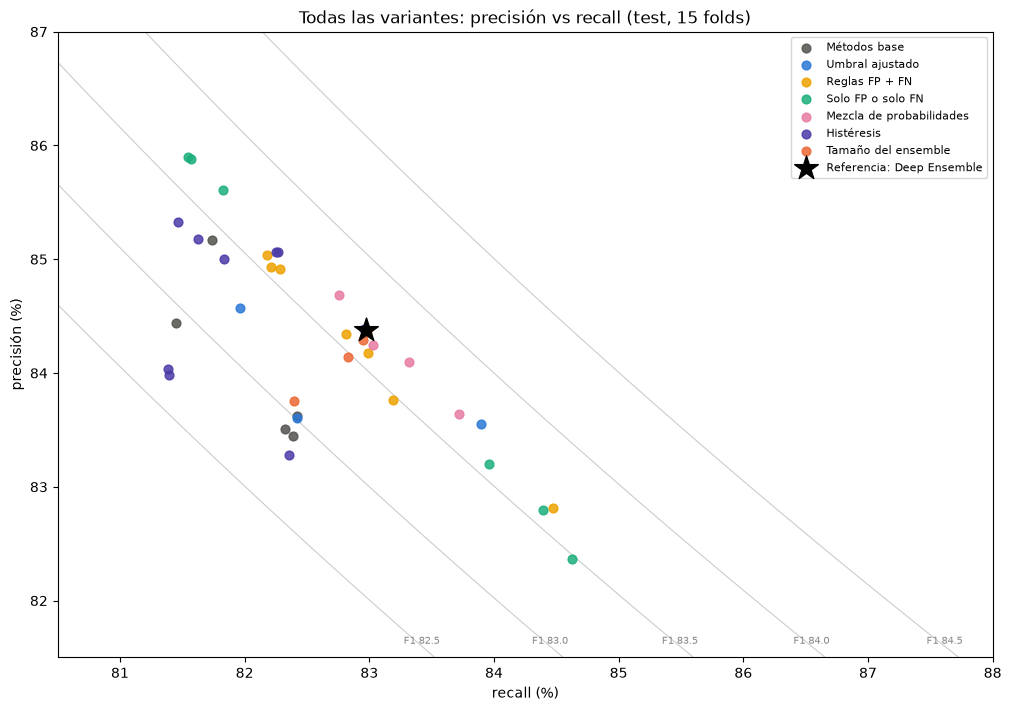

In [5]:
palette = ['#52514e', '#2a78d6', '#eda100', '#1baf7a', '#e87ba4', '#4a3aa7', '#eb6834', '#7fb3ec']
colors = {e.key: palette[i % len(palette)] for i, e in enumerate(es.EXPERIMENTS)}
fig, ax = plt.subplots(figsize=(10, 7), constrained_layout=True)
recall_grid = np.linspace(78, 88, 200)
for f1 in (82.5, 83.0, 83.5, 84.0, 84.5):
    precision = f1 * recall_grid / (2 * recall_grid - f1)
    ax.plot(recall_grid, precision, color='#cccccc', linewidth=0.8, zorder=0)
    label_precision = 81.6  # where each curve is labelled, inside the axes
    label_recall = f1 * label_precision / (2 * label_precision - f1)
    if 80.5 < label_recall < 88:
        ax.text(label_recall, label_precision, f'F1 {f1}', fontsize=7, color='#888888', ha='center', va='bottom')
for experiment, part in table.groupby('experimento', sort=False):
    ax.scatter(part['recall (%)'], part['precisión (%)'], s=40, color=colors[experiment], label=experiment, alpha=0.85)
ax.scatter([reference['recall (%)']], [reference['precisión (%)']], marker='*', s=320, color='black', label='Referencia: Deep Ensemble', zorder=5)
ax.set_xlim(80.5, 88)
ax.set_ylim(81.5, 87)
ax.set_xlabel('recall (%)')
ax.set_ylabel('precisión (%)')
ax.set_title('Todas las variantes: precisión vs recall (test, 15 folds)')
ax.legend(fontsize=8, loc='upper right')
show(fig)

### Cambio de F1 contra la referencia

Barra = Δ F1 promedio; línea = intervalo de confianza del 95% entre folds. Si el intervalo cruza el cero, el cambio no es confiable.

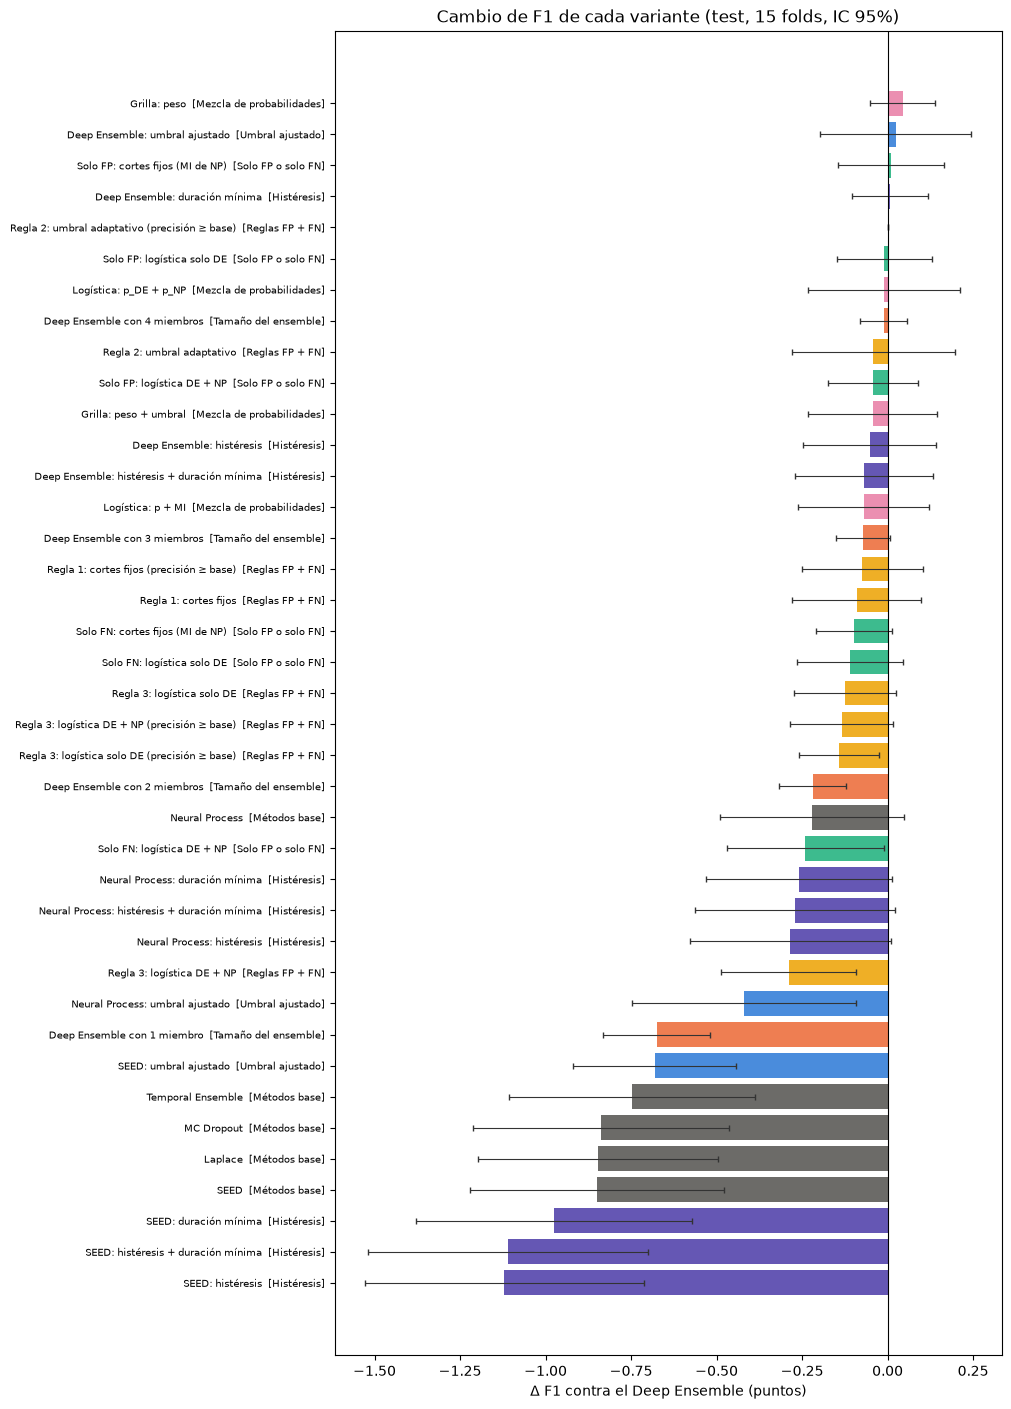

In [6]:
ordered = others.sort_values('Δ F1')
fig, ax = plt.subplots(figsize=(10, 0.32 * len(ordered) + 1.5), constrained_layout=True)
y = np.arange(len(ordered))
ax.barh(y, ordered['Δ F1'], xerr=ordered['IC95 Δ F1'], color=[colors[e] for e in ordered['experimento']],
        alpha=0.85, error_kw={'ecolor': '#333333', 'capsize': 2, 'linewidth': 0.8})
ax.set_yticks(y, [f"{v}  [{e}]" for e, v in zip(ordered['experimento'], ordered['variante'])], fontsize=7)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Δ F1 contra el Deep Ensemble (puntos)')
ax.set_title('Cambio de F1 de cada variante (test, 15 folds, IC 95%)')
show(fig)

## Conclusiones generales

*(Se actualizan con cada experimento nuevo.)*

1. **El Deep Ensemble con el umbral original es lo mejor en F1** (83.57%). Ningún experimento lo supera de forma confiable: los cambios van de −0.3 a +0.04 puntos, y ninguna mejora es significativa.
2. **La incertidumbre no reduce los errores; los cambia de lugar.** Las reglas que suben el recall bajan la precisión en la misma medida, y al revés. En el gráfico de precisión vs recall, todas las variantes quedan sobre la misma curva de F1 ≈ 83.5.
3. **Sí sirve para elegir el punto de operación:**
   - **Más precisión:** *Solo FP: logística solo DE*, precisión 85.9% (+1.5), recall 81.6%.
   - **Más recall:** *Regla 2: umbral adaptativo* (MI de Neural Process), recall 84.5% (+1.5), precisión 82.8%.
   - **Equilibrio:** el Deep Ensemble solo.
4. **Neural Process aporta poca información nueva sobre el Deep Ensemble.** Sus MI están correlacionadas (ρ ≈ 0.73) y la mezcla logística le da ~8% del peso. Lo único que mejora la mezcla es la **calibración** (ECE 0.0026 vs 0.0037).
5. **Cambiar el postprocesado tampoco ayuda.** La histéresis y otra duración mínima recuperan husos cortos (~+16 por fold), pero traen casi la misma cantidad de picos cortos de ruido (~+23 FP). El postprocesado original ya está bien ajustado.
6. **Más semillas iguales casi no suman.** El Deep Ensemble ya está cerca de su techo: ~83.68 con 10 semillas y ~83.77 con infinitas, solo +0.2 sobre el actual.
7. **El límite está en los husos débiles y en la anotación.** La mitad de los FN tiene probabilidad < 0.25: son husos reales pero débiles y cortos, que el modelo descarta **con seguridad** (errores silenciosos: la incertidumbre no los marca). Donde el modelo duda, ni la amplitud sigma distingue lo que el experto anotó de lo que no (AUROC ~0.5), y un tercio de los FP se parece a un huso típico. Ninguna regla, mezcla ni postprocesado puede superar esa ambigüedad. Para avanzar haría falta más información de la anotación (acuerdo entre expertos por huso) o un modelo más sensible a husos de baja amplitud, aceptando más FP.
8. **El uso más fuerte de la incertidumbre es la revisión humana.** No sirve para decidir sola mejor que la probabilidad, pero ordena bien qué revisar: el 20% de detecciones más inciertas contiene ~60% de los FP.